# OULAD Early Warning Analysis
### Industrial Mathematics Week 2026 —  Education

This notebook implements data analysis on the [Open University Learning Analytics Dataset (OULAD)](https://www.kaggle.com/datasets/anlgrbz/student-demographics-online-education-dataoulad/data).

**Structure:**

0. Setup & Imports
1. Data Loading
2. Preprocessing & Feature Engineering
3. **Descriptive Analytics**
4. **Diagnostic Analytics**
5. **Predictive Analytics**
6. **Recommendation & Intervention Analysis**
7. Conclusion


## 0. Setup & Imports

In [ ]:
!pip install -q kagglehub xgboost lightgbm shap lifelines plotly tslearn dtw-python "numba<=0.65.1"

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 8.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 401.7/401.7 kB 21.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 808.9/808.9 kB 25.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 23.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 8.9 MB/s eta 0:00:00


In [ ]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

# Advanced Analytics
from lifelines import KaplanMeierFitter
from tslearn.clustering import TimeSeriesKMeans
from tslearn.preprocessing import TimeSeriesScalerMeanVariance

# Machine Learning
from scipy.stats import mannwhitneyu, chi2_contingency, kruskal
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, precision_recall_curve, auc, brier_score_loss
import xgboost as xgb
import lightgbm as lgb
import shap

# Deep Learning
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# Plotting configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'figure.dpi': 100, 'font.size': 11})

OUTCOME_ORDER = ['Withdrawn', 'Fail', 'Pass', 'Distinction']
OUTCOME_COLORS = {'Withdrawn': '#d62728', 'Fail': '#ff7f0e', 'Pass': '#1f77b4', 'Distinction': '#2ca02c'}
pd.set_option('display.max_columns', 100)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")


Using device: cpu


## 1. Data Loading

In [ ]:
import kagglehub
path = kagglehub.dataset_download("anlgrbz/student-demographics-online-education-dataoulad")
print("Path to dataset files:", path)
DATA_DIR = path

studentInfo = pd.read_csv(f"{DATA_DIR}/studentInfo.csv")
studentRegistration = pd.read_csv(f"{DATA_DIR}/studentRegistration.csv")
courses = pd.read_csv(f"{DATA_DIR}/courses.csv")
assessments = pd.read_csv(f"{DATA_DIR}/assessments.csv")
vle = pd.read_csv(f"{DATA_DIR}/vle.csv")
studentVle = pd.read_csv(f"{DATA_DIR}/studentVle.csv")
studentAssessment = pd.read_csv(f"{DATA_DIR}/studentAssessment.csv")

tables = {'studentInfo': studentInfo, 'studentRegistration': studentRegistration, 'courses': courses,
          'assessments': assessments, 'vle': vle, 'studentVle': studentVle, 'studentAssessment': studentAssessment}
for name, df in tables.items():
    print(f"{name:22s} {df.shape}")


100%|██████████| 42.2M/42.2M [00:00<00:00, 46.3MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/anlgrbz/student-demographics-online-education-dataoulad/versions/1
studentInfo            (32593, 12)
studentRegistration    (32593, 5)
courses                (22, 3)
assessments            (206, 6)
vle                    (6364, 6)
studentVle             (10655280, 6)
studentAssessment      (173912, 5)


In [ ]:
studentInfo.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass


## 2.  Data Preprocessing & Cleaning

In [ ]:
for name, df in tables.items():
    na = df.isna().sum()
    na = na[na > 0]
    dup = df.duplicated().sum()
    print(f"--- {name} --- baris duplikat: {dup}")
    if len(na):
        print(na)

--- studentInfo --- baris duplikat: 0
imd_band    1111
dtype: int64
--- studentRegistration --- baris duplikat: 0
date_registration         45
date_unregistration    22521
dtype: int64
--- courses --- baris duplikat: 0
--- assessments --- baris duplikat: 0
date    11
dtype: int64
--- vle --- baris duplikat: 0
week_from    5243
week_to      5243
dtype: int64
--- studentVle --- baris duplikat: 787170
--- studentAssessment --- baris duplikat: 0
score    173
dtype: int64


`imd_band` (deprivation index) has missing values because some of the students are outside of England, we will mark these as 'Unknown' instead of deleting it because it still carries valuable information.

 `date_unregistration` missing values means the students didn't withdraw from the course (Pass/Fail/Distinction), we will also let this as it is.

In [ ]:
studentInfo['imd_band'] = studentInfo['imd_band'].fillna('Unknown')

age_order = ['0-35', '35-55', '55<=']
edu_order = ['No Formal quals', 'Lower Than A Level', 'A Level or Equivalent',
             'HE Qualification', 'Post Graduate Qualification']
imd_order = ['0-10%', '10-20%', '20-30%', '30-40%', '40-50%',
             '50-60%', '60-70%', '70-80%', '80-90%', '90-100%', 'Unknown']

studentInfo['age_band'] = pd.Categorical(studentInfo['age_band'], categories=age_order, ordered=True)
studentInfo['highest_education'] = pd.Categorical(studentInfo['highest_education'], categories=edu_order, ordered=True)
studentInfo['imd_band'] = pd.Categorical(studentInfo['imd_band'], categories=imd_order, ordered=True)
studentInfo['final_result'] = pd.Categorical(studentInfo['final_result'], categories=OUTCOME_ORDER, ordered=True)

print(studentInfo[['age_band','highest_education','imd_band','final_result']].nunique())

age_band              3
highest_education     5
imd_band             10
final_result          4
dtype: int64


Binary lable **at-risk** is defined by `Fail` or `Withdrawn` (based on this dataset), while `Pass` and `Distinction` are considered as a good result.

In [ ]:
studentInfo['at_risk'] = studentInfo['final_result'].isin(['Fail', 'Withdrawn']).astype(int)
studentVle['week'] = studentVle['date'] // 7
studentAssessment_full = studentAssessment.merge(assessments, on='id_assessment', how='left')

In [ ]:
df_main = studentInfo.merge(
    studentRegistration[['code_module','code_presentation','id_student','date_registration','date_unregistration']],
    on=['code_module','code_presentation','id_student'], how='left'
)
print(df_main.shape)
df_main.head(3)

(32593, 15)


,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,at_risk,date_registration,date_unregistration
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,0,-159.0,NaN
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,0,-53.0,NaN
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,1,-92.0,12.0


### Cleaning

In [ ]:
# Clean categorical variables
studentInfo['imd_band'] = studentInfo['imd_band'].fillna('Unknown')
studentInfo['at_risk'] = studentInfo['final_result'].isin(['Fail', 'Withdrawn']).astype(int)

age_order = ['0-35', '35-55', '55<=']
edu_order = ['No Formal quals', 'Lower Than A Level', 'A Level or Equivalent',
             'HE Qualification', 'Post Graduate Qualification']
imd_order = ['0-10%', '10-20%', '20-30%', '30-40%', '40-50%',
             '50-60%', '60-70%', '70-80%', '80-90%', '90-100%', 'Unknown']

studentInfo['age_band'] = pd.Categorical(studentInfo['age_band'], categories=age_order, ordered=True)
studentInfo['highest_education'] = pd.Categorical(studentInfo['highest_education'], categories=edu_order, ordered=True)
studentInfo['imd_band'] = pd.Categorical(studentInfo['imd_band'], categories=imd_order, ordered=True)
studentInfo['final_result'] = pd.Categorical(studentInfo['final_result'], categories=OUTCOME_ORDER, ordered=True)

# Merge registration timing
df_main = studentInfo.merge(
    studentRegistration[['code_module','code_presentation','id_student','date_registration','date_unregistration']],
    on=['code_module','code_presentation','id_student'], how='left'
)

# Feature Engineering: Registration Timing
df_main['registered_early'] = (df_main['date_registration'] < 0).astype(int)
df_main['registration_delay'] = df_main['date_registration'].clip(lower=0)

# Target encoding for modules (smooth)
module_risk = df_main.groupby('code_module')['at_risk'].mean().to_dict()
df_main['module_risk_rate'] = df_main['code_module'].map(module_risk)


In [ ]:
studentInfo.head()

,code_module,code_presentation,id_student,gender,region,highest_education,imd_band,age_band,num_of_prev_attempts,studied_credits,disability,final_result,at_risk
0,AAA,2013J,11391,M,East Anglian Region,HE Qualification,90-100%,55<=,0,240,N,Pass,0
1,AAA,2013J,28400,F,Scotland,HE Qualification,20-30%,35-55,0,60,N,Pass,0
2,AAA,2013J,30268,F,North Western Region,A Level or Equivalent,30-40%,35-55,0,60,Y,Withdrawn,1
3,AAA,2013J,31604,F,South East Region,A Level or Equivalent,50-60%,35-55,0,60,N,Pass,0
4,AAA,2013J,32885,F,West Midlands Region,Lower Than A Level,50-60%,0-35,0,60,N,Pass,0


In [ ]:
# Enhance VLE data with activity types
studentVle = studentVle.merge(vle[['id_site', 'activity_type']], on='id_site', how='left')
studentVle['week'] = studentVle['date'] // 7

# Categorize activity types broadly
activity_groups = {
    'forumng': 'Communication',
    'oucontent': 'Content',
    'resource': 'Content',
    'subpage': 'Navigation',
    'homepage': 'Navigation',
    'url': 'Content',
    'quiz': 'Assessment',
    'oucollaborate': 'Communication'
}
studentVle['activity_group'] = studentVle['activity_type'].map(lambda x: activity_groups.get(x, 'Other'))
print("VLE enriched with activity types.")

# Enhance Assessment data with submission behaviors
sa = studentAssessment.merge(assessments, on='id_assessment', how='left')
sa = sa.merge(studentInfo[['code_module','code_presentation','id_student','final_result', 'at_risk']],
              on=['code_module','code_presentation','id_student'], how='left')
sa = sa[sa['assessment_type'] != 'Exam'].copy()
sa['days_late'] = sa['date_submitted'] - sa['date']
sa['is_late'] = (sa['days_late'] > 0).astype(int)
sa['assess_order'] = sa.groupby(['code_module','code_presentation'])['date'].rank(method='dense')
print("Assessments enriched with timing and ordering.")


VLE enriched with activity types.
Assessments enriched with timing and ordering.


## 3. Descriptive Analytics

In [ ]:
n_students = studentInfo['id_student'].nunique()
n_enrolments = len(studentInfo)
n_modules = studentInfo['code_module'].nunique()
n_presentations = studentInfo[['code_module','code_presentation']].drop_duplicates().shape[0]

print(f"Jumlah mahasiswa unik      : {n_students:,}")
print(f"Jumlah baris pendaftaran   : {n_enrolments:,} (mahasiswa bisa ambil >1 presentasi/modul)")
print(f"Jumlah modul               : {n_modules}")
print(f"Jumlah presentasi modul    : {n_presentations}")

Jumlah mahasiswa unik      : 28,785
Jumlah baris pendaftaran   : 32,593 (mahasiswa bisa ambil >1 presentasi/modul)
Jumlah modul               : 7
Jumlah presentasi modul    : 22


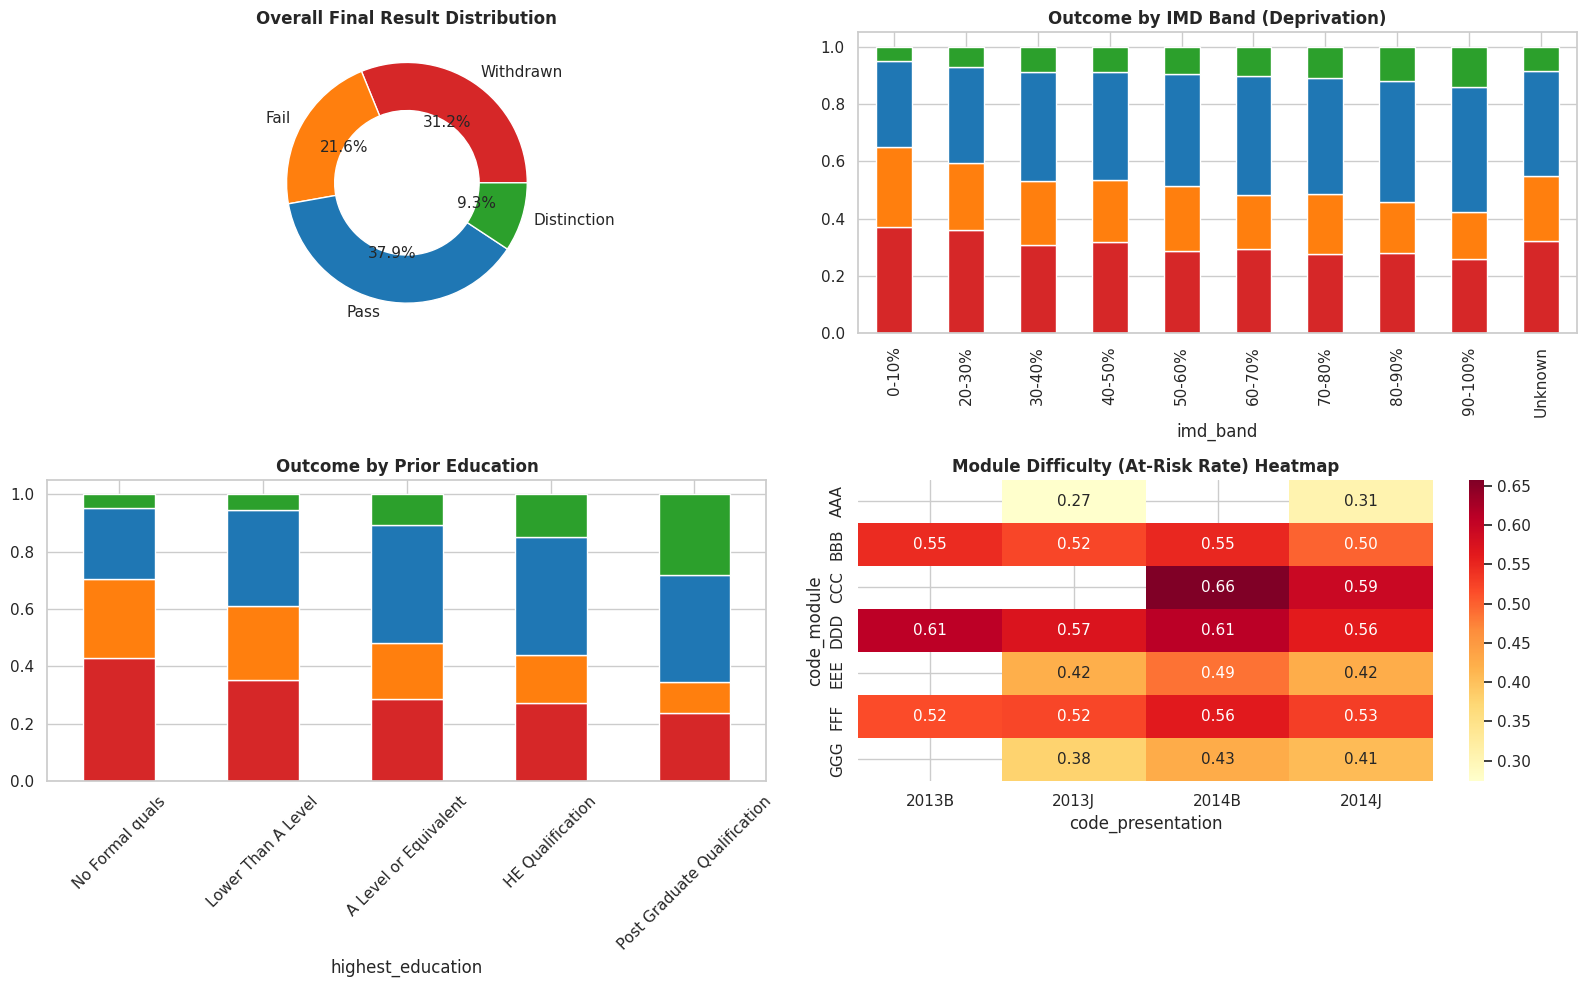

In [ ]:
# Population & Outcome Overview
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

vc = studentInfo['final_result'].value_counts()[OUTCOME_ORDER]
axes[0,0].pie(vc, labels=vc.index, autopct='%1.1f%%', colors=[OUTCOME_COLORS[o] for o in OUTCOME_ORDER], wedgeprops=dict(width=0.4))
axes[0,0].set_title('Overall Final Result Distribution', fontweight='bold')

ct_imd = pd.crosstab(studentInfo['imd_band'], studentInfo['final_result'], normalize='index')[OUTCOME_ORDER]
ct_imd.plot(kind='bar', stacked=True, ax=axes[0,1], color=[OUTCOME_COLORS[o] for o in OUTCOME_ORDER])
axes[0,1].set_title('Outcome by IMD Band (Deprivation)', fontweight='bold')
axes[0,1].legend().remove()

ct_edu = pd.crosstab(studentInfo['highest_education'], studentInfo['final_result'], normalize='index')[OUTCOME_ORDER]
ct_edu.plot(kind='bar', stacked=True, ax=axes[1,0], color=[OUTCOME_COLORS[o] for o in OUTCOME_ORDER])
axes[1,0].set_title('Outcome by Prior Education', fontweight='bold')
axes[1,0].legend().remove()
axes[1,0].tick_params(axis='x', rotation=45)

ct_mod = pd.crosstab(studentInfo['code_module'], studentInfo['code_presentation'], values=studentInfo['at_risk'], aggfunc='mean')
sns.heatmap(ct_mod, annot=True, fmt=".2f", cmap="YlOrRd", ax=axes[1,1])
axes[1,1].set_title('Module Difficulty (At-Risk Rate) Heatmap', fontweight='bold')

plt.tight_layout()
plt.show()


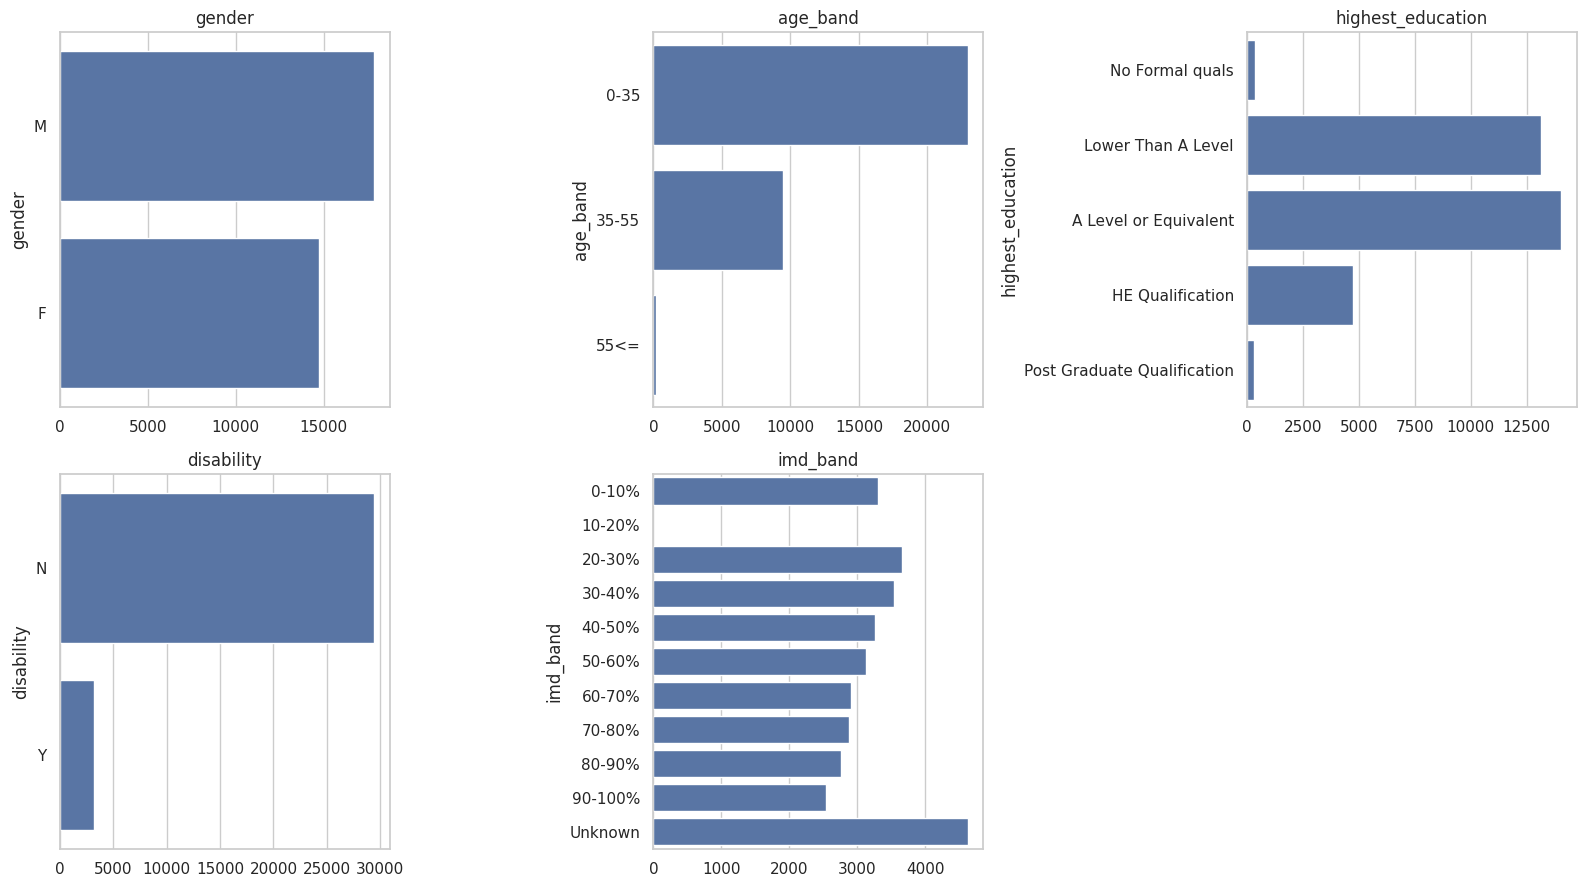

In [ ]:
# Komposisi Demografis
demo_cols = ['gender','age_band','highest_education','disability','imd_band']
fig, axes = plt.subplots(2, 3, figsize=(16,9))
axes = axes.flatten()
for i, col in enumerate(demo_cols):
    order = studentInfo[col].cat.categories if hasattr(studentInfo[col],'cat') else None
    sns.countplot(data=studentInfo, y=col, order=order, ax=axes[i], color='#4C72B0')
    axes[i].set_title(col)
    axes[i].set_xlabel('')
axes[-1].axis('off')
plt.tight_layout()
plt.show()

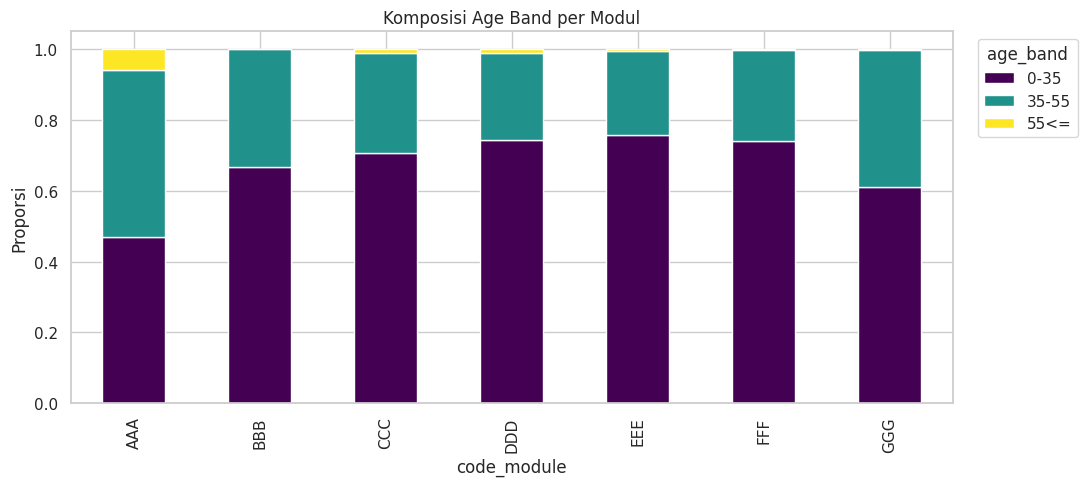

In [ ]:
fig, ax = plt.subplots(figsize=(11,5))
ct = pd.crosstab(studentInfo['code_module'], studentInfo['age_band'], normalize='index')
ct.plot(kind='bar', stacked=True, ax=ax, colormap='viridis')
ax.set_ylabel('Proporsi')
ax.set_title('Komposisi Age Band per Modul')
ax.legend(title='age_band', bbox_to_anchor=(1.02,1), loc='upper left')
plt.tight_layout()
plt.show()

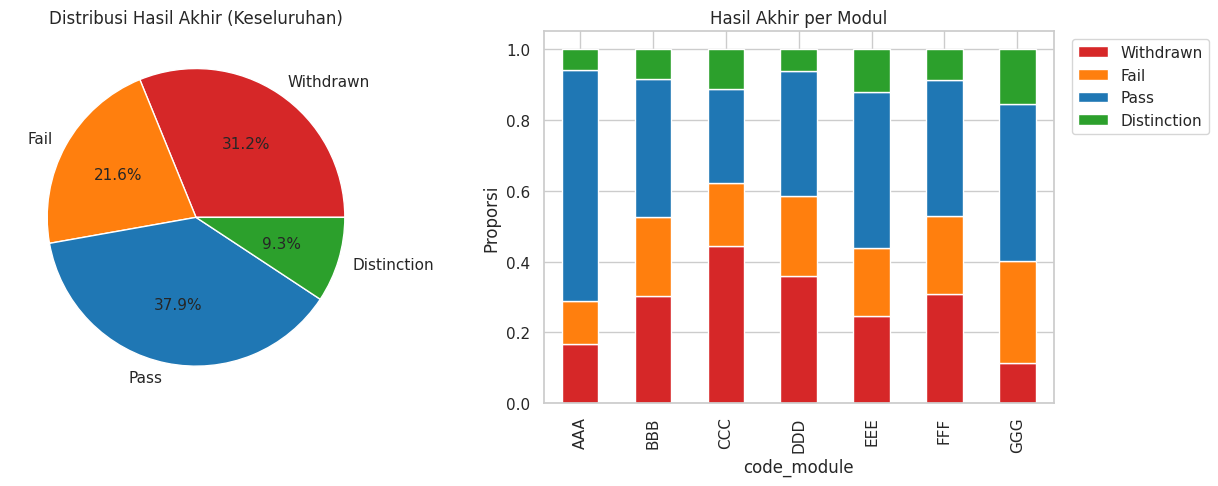

52.8 % pendaftaran berujung Fail/Withdrawn


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13,5))
vc = studentInfo['final_result'].value_counts()[OUTCOME_ORDER]
axes[0].pie(vc, labels=vc.index, autopct='%1.1f%%', colors=[OUTCOME_COLORS[o] for o in OUTCOME_ORDER])
axes[0].set_title('Distribusi Hasil Akhir (Keseluruhan)')

ct = pd.crosstab(studentInfo['code_module'], studentInfo['final_result'], normalize='index')[OUTCOME_ORDER]
ct.plot(kind='bar', stacked=True, ax=axes[1], color=[OUTCOME_COLORS[o] for o in OUTCOME_ORDER])
axes[1].set_ylabel('Proporsi')
axes[1].set_title('Hasil Akhir per Modul')
axes[1].legend(bbox_to_anchor=(1.02,1), loc='upper left')
plt.tight_layout()
plt.show()
print((studentInfo['at_risk'].mean()*100).round(1), "% pendaftaran berujung Fail/Withdrawn")

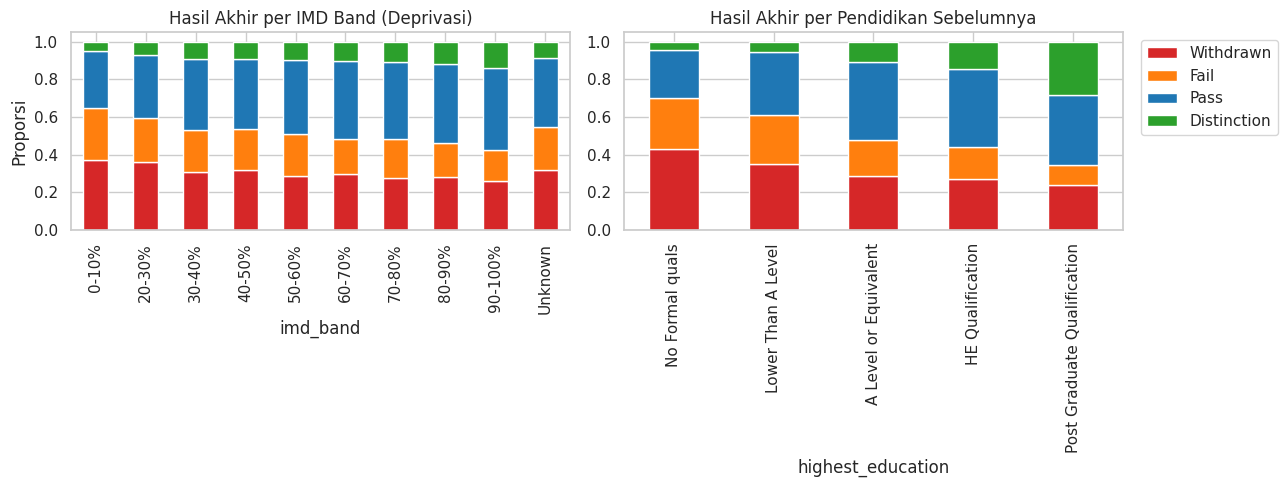

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13,5))
ct1 = pd.crosstab(studentInfo['imd_band'], studentInfo['final_result'], normalize='index')[OUTCOME_ORDER]
ct1.plot(kind='bar', stacked=True, ax=axes[0], color=[OUTCOME_COLORS[o] for o in OUTCOME_ORDER])
axes[0].set_title('Hasil Akhir per IMD Band (Deprivasi)')
axes[0].set_ylabel('Proporsi')
axes[0].legend().remove()

ct2 = pd.crosstab(studentInfo['highest_education'], studentInfo['final_result'], normalize='index')[OUTCOME_ORDER]
ct2.plot(kind='bar', stacked=True, ax=axes[1], color=[OUTCOME_COLORS[o] for o in OUTCOME_ORDER])
axes[1].set_title('Hasil Akhir per Pendidikan Sebelumnya')
axes[1].set_ylabel('')
axes[1].legend(bbox_to_anchor=(1.02,1), loc='upper left')
plt.tight_layout()
plt.show()

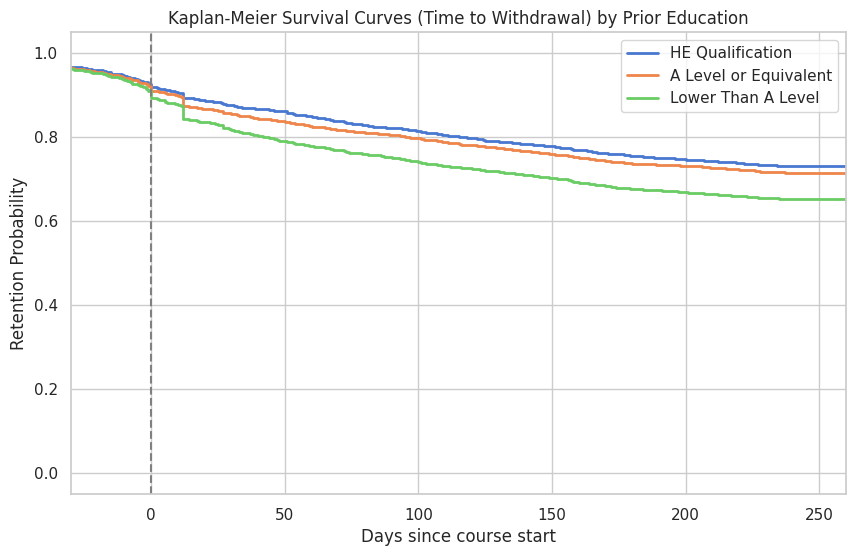

In [ ]:
#  Survival Analysis: Time to Withdrawal
plt.figure(figsize=(10, 6))
kmf = KaplanMeierFitter()

surv_df = df_main.copy()
surv_df['duration'] = surv_df['date_unregistration'].fillna(260)
surv_df['event'] = (surv_df['final_result'] == 'Withdrawn').astype(int)

for edu in surv_df['highest_education'].dropna().unique():
    mask = surv_df['highest_education'] == edu
    if mask.sum() > 500:
        kmf.fit(surv_df.loc[mask, 'duration'], surv_df.loc[mask, 'event'], label=str(edu))
        kmf.plot_survival_function(ci_show=False, linewidth=2)

plt.title("Kaplan-Meier Survival Curves (Time to Withdrawal) by Prior Education")
plt.xlabel("Days since course start")
plt.ylabel("Retention Probability")
plt.axvline(0, color='grey', linestyle='--')
plt.xlim(-30, 260)
plt.show()


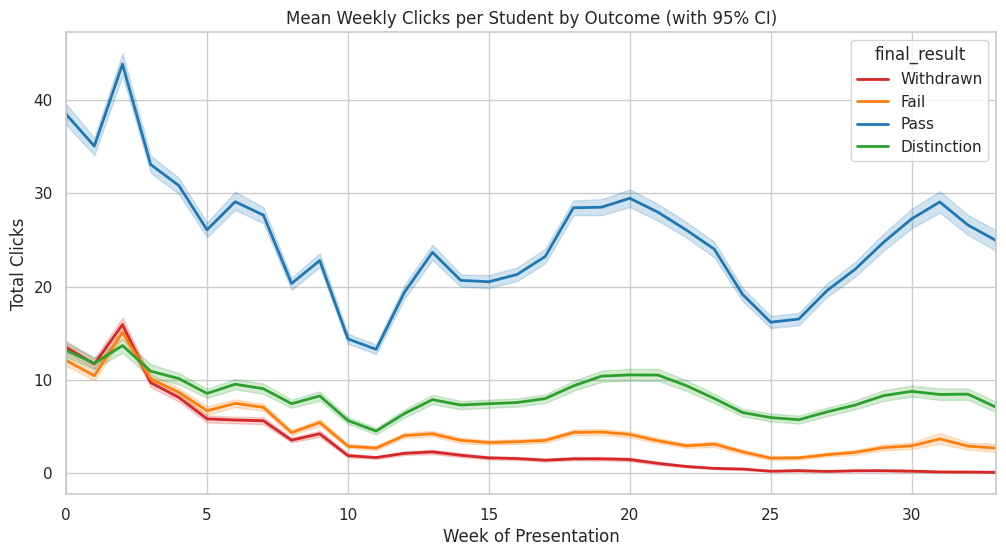

In [ ]:
# Engagement Trajectories with Confidence Bands
daily = studentVle.merge(
    studentInfo[['code_module','code_presentation','id_student','final_result']],
    on=['code_module','code_presentation','id_student'], how='left'
)
weekly_student = daily.groupby(['id_student', 'final_result', 'week'])['sum_click'].sum().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=weekly_student[(weekly_student['week']>=0) & (weekly_student['week']<=35)],
             x='week', y='sum_click', hue='final_result', hue_order=OUTCOME_ORDER,
             palette=OUTCOME_COLORS, errorbar=('ci', 95), linewidth=2)
plt.title('Mean Weekly Clicks per Student by Outcome (with 95% CI)')
plt.xlabel('Week of Presentation')
plt.ylabel('Total Clicks')
plt.xlim(0, 33)
plt.show()


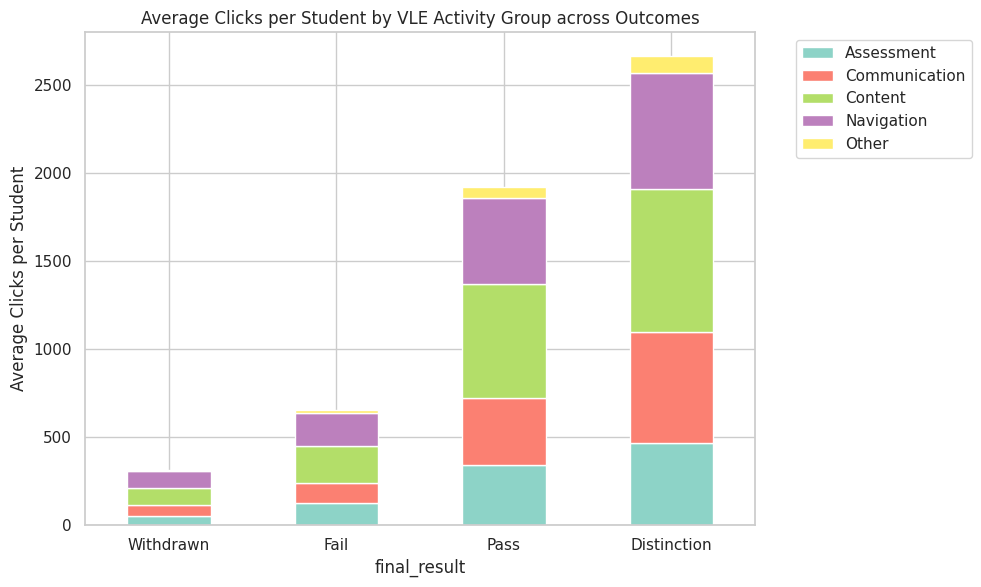

In [ ]:
#  VLE Activity Type Breakdown
activity_summary = daily.groupby(['final_result', 'activity_group'])['sum_click'].sum().unstack(fill_value=0)
n_students_per_outcome = studentInfo['final_result'].value_counts()
activity_summary = activity_summary.div(n_students_per_outcome, axis=0)

activity_summary.loc[OUTCOME_ORDER].plot(kind='bar', stacked=True, figsize=(10, 6), colormap='Set3')
plt.title('Average Clicks per Student by VLE Activity Group across Outcomes')
plt.ylabel('Average Clicks per Student')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


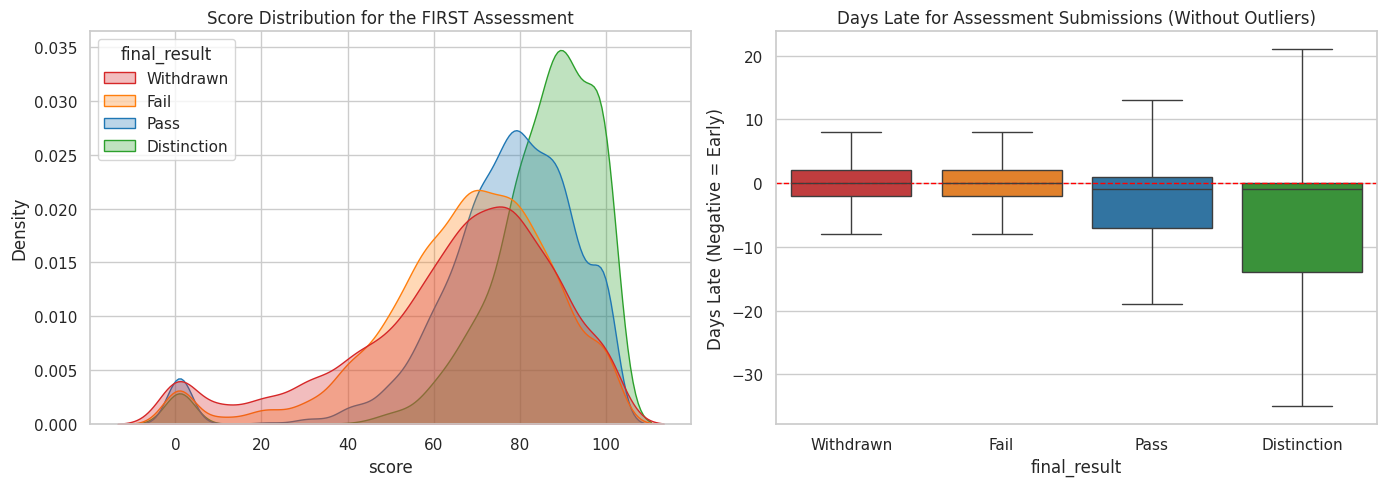

In [ ]:
#  Assessment Score KDE and Submission Timing
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

early_sa = sa[sa['assess_order'] == 1]
sns.kdeplot(data=early_sa, x='score', hue='final_result', hue_order=OUTCOME_ORDER,
            palette=OUTCOME_COLORS, common_norm=False, fill=True, ax=axes[0], alpha=0.3)
axes[0].set_title('Score Distribution for the FIRST Assessment')

sns.boxplot(data=sa, x='final_result', y='days_late', order=OUTCOME_ORDER,
            palette=OUTCOME_COLORS, ax=axes[1], showfliers=False)
axes[1].axhline(0, color='red', linestyle='--', linewidth=1)
axes[1].set_title('Days Late for Assessment Submissions (Without Outliers)')
axes[1].set_ylabel('Days Late (Negative = Early)')

plt.tight_layout()
plt.show()


The population is dominated by students aged 0–35, with a relatively consistent demographic composition across modules.

Around one-third to one-half of registrations end up at-risk (Fail/Withdrawn), with variations across modules and a higher tendency among low IMD bands and minimal prior education.

Weekly engagement is the clearest differentiator: Withdrawn drops sharply and ceases early; Distinction is consistently high; Pass vs Fail only separates clearly midway through the presentation.

Assignment scores from the beginning of the presentation already differentiate the final outcome groups, making them strong feature candidates for early prediction.

## 4. Diagnostic Analytics
This phase shifts our focus from pattern recognition to causal explanation, like answering **why** certain student behaviors occur and identifying the root drivers of failure or withdrawal.
We run two focused investigations, each grounded in one or more formal statistical hypothesis tests.

### 4.1 Investigation 1 — Early Engagement and Outcome Divergence

We compared the cumulative VLE clicks at each checkpoint (weeks 2, 4, 8, and 12) between students who eventually passed or earned a distinction and those who failed or withdrew. For this analysis, we used the **Mann-Whitney U test** because the click counts were heavily skewed, making it much more appropriate to compare medians and ranks rather than standard means.

With a sample size of over 32,000 students, a small p-value alone does not provide strong evidence. At this scale, even a trivial difference in clicks can appear statistically significant. Therefore, we only considered a checkpoint to show a meaningful divergence if three criteria aligned simultaneously: a small p-value, a non-trivial **rank-biserial effect size**, and a **univariate AUC** visibly above 0.5. By examining all four checkpoints, we can determine whether this performance gap emerges early enough to be actionable (weeks 2 to 4) or if it only becomes apparent later in the term (weeks 8 to 12) when it is too late to intervene.

In [ ]:
# Engagement Feature at Each Checkpoint
merge_keys = ['code_module', 'code_presentation', 'id_student']
checkpoint_weeks = [2, 4, 8, 12]

engagement_features = df_main[merge_keys + ['at_risk', 'final_result']].copy()

for wk in checkpoint_weeks:
    cum = (studentVle[(studentVle['week'] >= 0) & (studentVle['week'] < wk)]
           .groupby(merge_keys)['sum_click'].sum()
           .rename(f'clicks_w{wk}'))
    engagement_features = engagement_features.merge(cum, on=merge_keys, how='left')

click_cols = [f'clicks_w{wk}' for wk in checkpoint_weeks]
engagement_features[click_cols] = engagement_features[click_cols].fillna(0)

engagement_features.head()

,code_module,code_presentation,id_student,at_risk,final_result,clicks_w2,clicks_w4,clicks_w8,clicks_w12
0,AAA,2013J,11391,0,Pass,203.0,303.0,431.0,487.0
1,AAA,2013J,28400,0,Pass,241.0,335.0,454.0,547.0
2,AAA,2013J,30268,1,Withdrawn,179.0,179.0,179.0,179.0
3,AAA,2013J,31604,0,Pass,176.0,309.0,635.0,784.0
4,AAA,2013J,32885,0,Pass,177.0,272.0,306.0,381.0


In [ ]:
# Mann-Whitney U, Effect Size, AUC
h1_results = []

for wk in checkpoint_weeks:
    col = f'clicks_w{wk}'
    g_pass = engagement_features.loc[engagement_features['at_risk'] == 0, col]
    g_risk = engagement_features.loc[engagement_features['at_risk'] == 1, col]

    u_stat, p_val = mannwhitneyu(g_pass, g_risk, alternative='two-sided')
    n1, n2 = len(g_pass), len(g_risk)
    rank_biserial = 1 - (2 * u_stat) / (n1 * n2)

    # Sign flipped so AUC > 0.5 reflects genuine separability of the at-risk class
    auc = roc_auc_score(engagement_features['at_risk'], -engagement_features[col])

    h1_results.append({
        'week': wk, 'n_pass': n1, 'n_at_risk': n2,
        'median_clicks_pass': g_pass.median(), 'median_clicks_at_risk': g_risk.median(),
        'U_statistic': u_stat, 'p_value': p_val,
        'rank_biserial_effect_size': rank_biserial, 'AUC_engagement_only': auc
    })

h1_df = pd.DataFrame(h1_results)
h1_df

,week,n_pass,n_at_risk,median_clicks_pass,median_clicks_at_risk,U_statistic,p_value,rank_biserial_effect_size,AUC_engagement_only
0,2,15385,17208,104.0,23.0,191857348.5,0.0,-0.449374,0.724687
1,4,15385,17208,231.0,66.0,194326097.0,0.0,-0.468024,0.734012
2,8,15385,17208,401.0,103.0,202191258.0,0.0,-0.527441,0.763721
3,12,15385,17208,508.0,118.0,206556475.5,0.0,-0.560418,0.780209


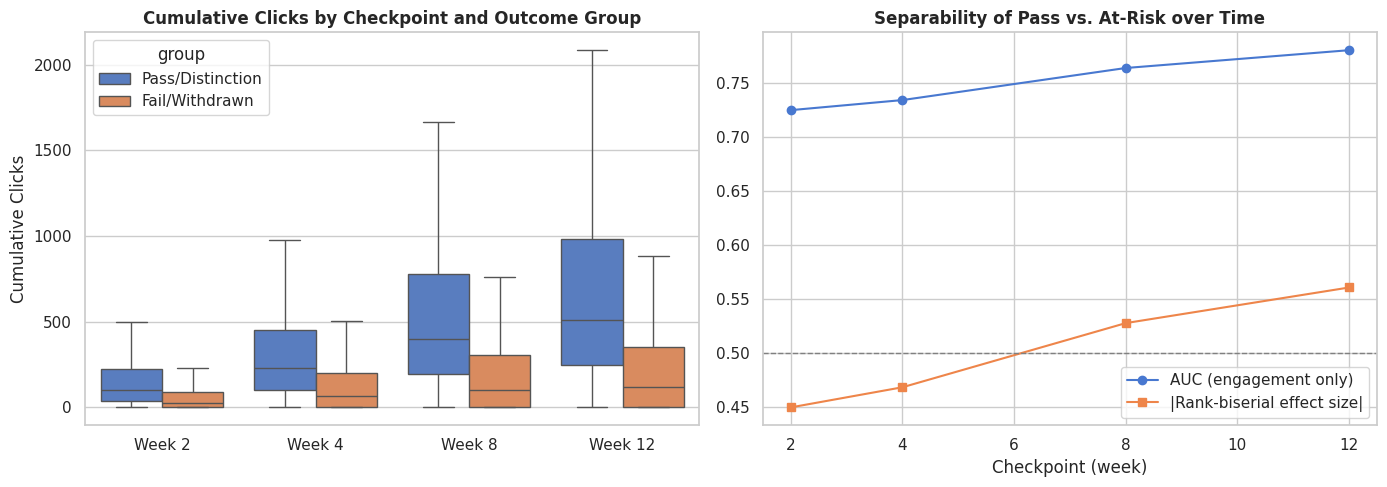

 week  p_value  rank_biserial_effect_size  AUC_engagement_only
    2      0.0                  -0.449374             0.724687
    4      0.0                  -0.468024             0.734012
    8      0.0                  -0.527441             0.763721
   12      0.0                  -0.560418             0.780209


In [ ]:
# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

melted = engagement_features.melt(
    id_vars=['at_risk'], value_vars=click_cols,
    var_name='checkpoint', value_name='cum_clicks'
)
melted['checkpoint'] = melted['checkpoint'].str.replace('clicks_w', 'Week ')
melted['group'] = melted['at_risk'].map({0: 'Pass/Distinction', 1: 'Fail/Withdrawn'})

sns.boxplot(data=melted, x='checkpoint', y='cum_clicks', hue='group', showfliers=False, ax=axes[0])
axes[0].set_title('Cumulative Clicks by Checkpoint and Outcome Group', fontweight='bold')
axes[0].set_ylabel('Cumulative Clicks')
axes[0].set_xlabel('')

axes[1].plot(h1_df['week'], h1_df['AUC_engagement_only'], marker='o', label='AUC (engagement only)')
axes[1].plot(h1_df['week'], h1_df['rank_biserial_effect_size'].abs(), marker='s', label='|Rank-biserial effect size|')
axes[1].axhline(0.5, color='grey', linestyle='--', linewidth=1)
axes[1].set_title('Separability of Pass vs. At-Risk over Time', fontweight='bold')
axes[1].set_xlabel('Checkpoint (week)')
axes[1].legend()

plt.tight_layout()
plt.show()

print(h1_df[['week', 'p_value', 'rank_biserial_effect_size', 'AUC_engagement_only']].to_string(index=False))

**Interpretation:**
* At every checkpoint, the p-value is effectively 0. Given the large sample size (N>32,000), this statistical significance is expected. Therefore, we rely on the effect size and AUC to evaluate the actual strength of the findings.
* The engagement gap between the two groups is already substantial by Week 2. At this earliest checkpoint, the rank-biserial effect size is −0.45 and the univariate AUC is 0.72, meaning cumulative clicks alone can already differentiate future outcomes noticeably better than chance.
* Although the signal strengthens through Week 12 (effect size: −0.56, AUC: 0.78), the improvement after Week 2 is modest (AUC increases by only +0.06). The boxplots visually confirm this, showing a clear, consistent gap between the medians from the very beginning.

These results strongly support the early-engagement hypothesis. The divergence is clearly visible by Week 2 rather than emerging late in the term. Consequently, institutions do not need to wait until Weeks 8–12 to identify at-risk students. Week 2–4 checkpoint already provides a meaningful predictive signal, offering a much longer runway for timely intervention.



### 4.2 Investigation 2 — Demographic or SES Risk Independent of Engagement
We first evaluated whether each demographic and socioeconomic status (SES) variable, including age band, prior education, deprivation band, and disability status, was associated with at-risk status on its own. For this initial screening, we ran a separate **chi-square test** of independence for each individual variable.

However, a demographic group might appear at risk simply because its members happen to be less engaged overall. To account for this, we fitted a **logistic regression model** that included all demographic variables together, alongside early engagement (measured as log-transformed cumulative clicks by week 4) and a control for module difficulty `module_risk_rate`. A demographic factor is considered an independent risk driver only if its effect remains statistically significant after adjusting for these variables. If a factor is significant on its own but loses that significance once we account for engagement, it indicates that the apparent risk was actually driven by lower engagement levels rather than the demographic trait itself.

In [ ]:
# Univariate Chi-square Test
demo_vars = ['age_band', 'highest_education', 'imd_band', 'disability']
univariate_results = []

for var in demo_vars:
    ct = pd.crosstab(df_main[var], df_main['at_risk'])
    chi2, p, dof, _ = chi2_contingency(ct)
    univariate_results.append({'variable': var, 'chi2': chi2, 'dof': dof, 'p_value': p})

univariate_df = pd.DataFrame(univariate_results)
univariate_df

,variable,chi2,dof,p_value
0,age_band,154.221665,2,3.244822e-34
1,highest_education,737.245271,4,2.999038e-158
2,imd_band,473.495577,9,2.707317e-96
3,disability,114.897684,1,8.286448e-27


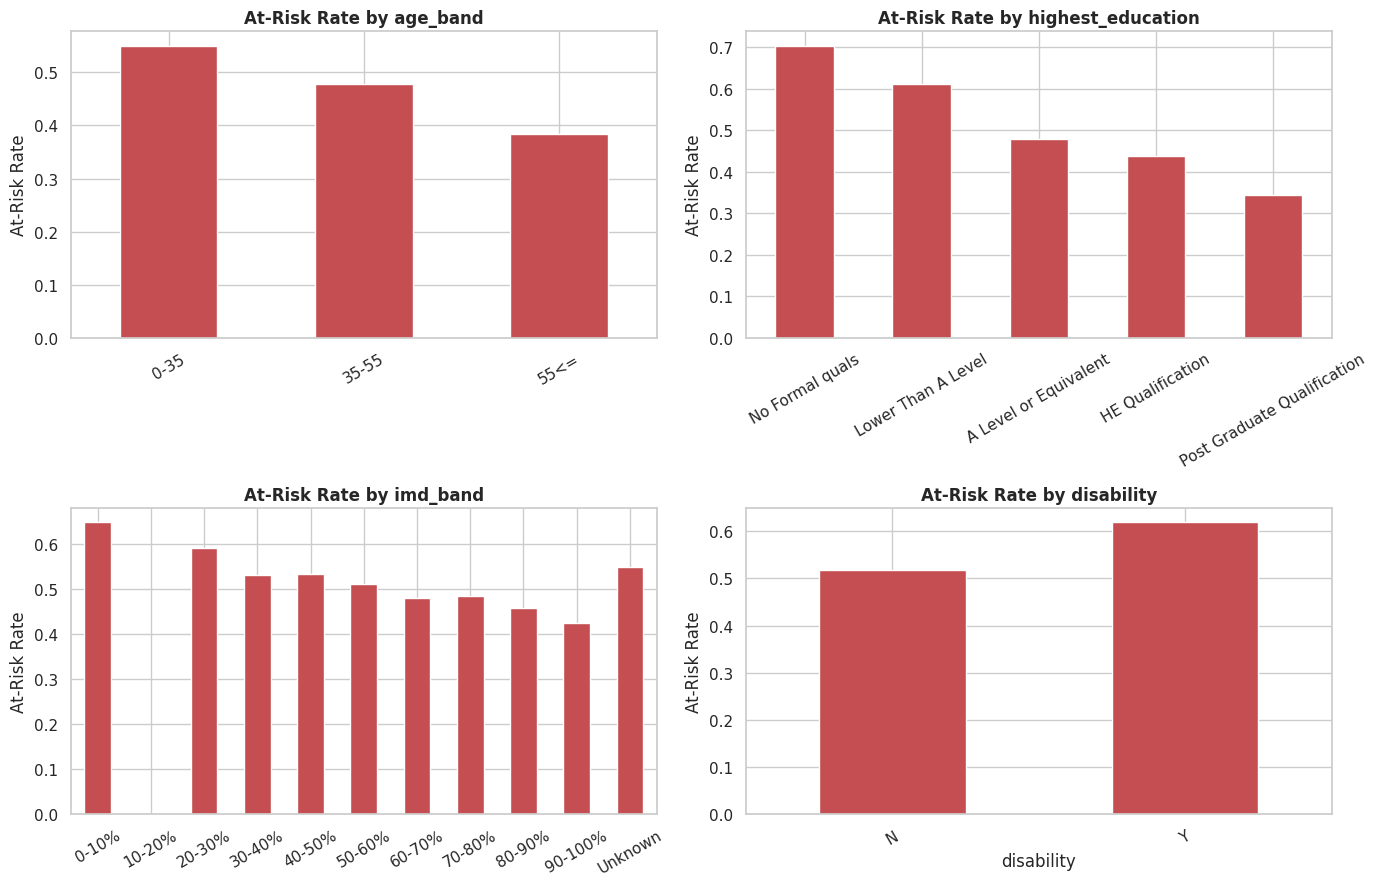

In [ ]:
# Visualization of Raw At-Risk Rates
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()
for i, var in enumerate(demo_vars):
    rate = df_main.groupby(var)['at_risk'].mean()
    order = rate.index if not hasattr(df_main[var], 'cat') else df_main[var].cat.categories
    rate = rate.reindex(order)
    rate.plot(kind='bar', ax=axes[i], color='#C44E52')
    axes[i].set_title(f'At-Risk Rate by {var}', fontweight='bold')
    axes[i].set_ylabel('At-Risk Rate')
    axes[i].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
reg_data = df_main.merge(
    engagement_features[merge_keys + ['clicks_w4']],
    on=merge_keys, how='left'
)
reg_data['log_clicks_w4'] = np.log1p(reg_data['clicks_w4'])
reg_data = reg_data.dropna(subset=demo_vars + ['log_clicks_w4', 'module_risk_rate', 'at_risk'])

for var in demo_vars:
    if hasattr(reg_data[var], 'cat'):
        reg_data[var] = reg_data[var].cat.remove_unused_categories()

# Standardize continuous predictors so their odds ratios are "per 1 SD",
# comparable in scale to the categorical dummies instead of "per 1 full unit"
reg_data['log_clicks_w4_z'] = (reg_data['log_clicks_w4'] - reg_data['log_clicks_w4'].mean()) / reg_data['log_clicks_w4'].std()
reg_data['module_risk_rate_z'] = (reg_data['module_risk_rate'] - reg_data['module_risk_rate'].mean()) / reg_data['module_risk_rate'].std()

formula = (
    "at_risk ~ C(age_band) + C(highest_education) + C(imd_band) + C(disability) "
    "+ log_clicks_w4_z + module_risk_rate_z"
)
logit_model = smf.logit(formula=formula, data=reg_data).fit(method='bfgs', maxiter=200, disp=0)
print(logit_model.summary())

                           Logit Regression Results                           
Dep. Variable:                at_risk   No. Observations:                32593
Model:                          Logit   Df Residuals:                    32574
Method:                           MLE   Df Model:                           18
Date:                Wed, 15 Jul 2026   Pseudo R-squ.:                  0.1893
Time:                        04:31:38   Log-Likelihood:                -18273.
converged:                       True   LL-Null:                       -22541.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                          coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------------------
Intercept                                               1.0827      0.135      8.041      0.000       0.819       1.347
C(age_ba

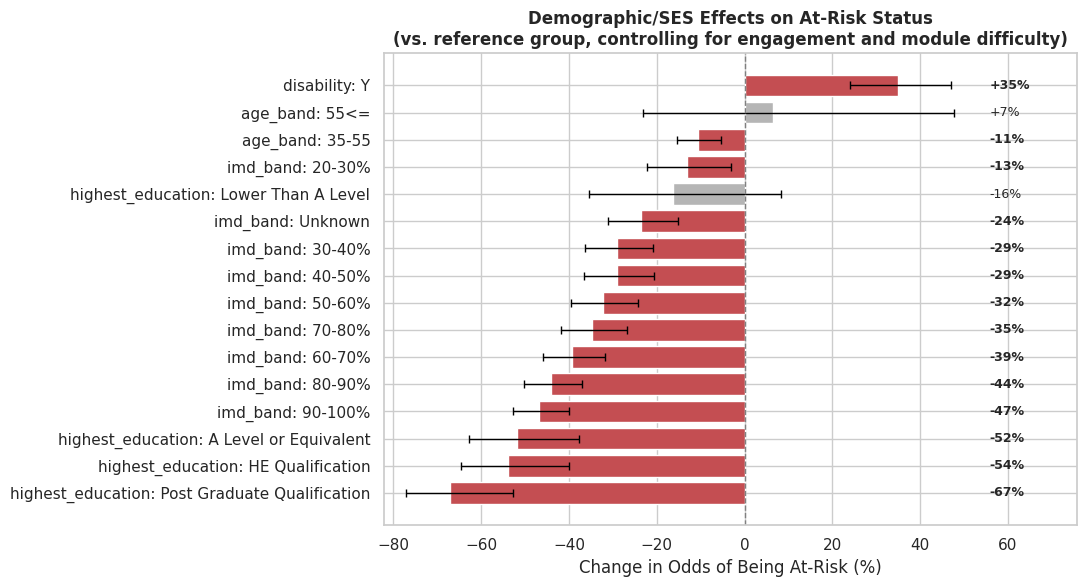

Red = statistically significant (p < 0.05): we're confident this group's risk genuinely differs
from the reference group. Gray = not significant: the confidence interval crosses 0%, so we
can't rule out that the apparent difference is just random sampling noise.


In [ ]:
fig, ax = plt.subplots(figsize=(11, max(6, 0.35 * len(or_df))))
colors = ['#C44E52' if p < 0.05 else '#B5B5B5' for p in or_df['p_value']]

ax.barh(or_df['label'], or_df['pct_change'], color=colors)
ax.errorbar(
    or_df['pct_change'], range(len(or_df)),
    xerr=[or_df['pct_change'] - or_df['pct_ci_low'], or_df['pct_ci_high'] - or_df['pct_change']],
    fmt='none', ecolor='black', capsize=3, linewidth=1
)

ax.axvline(0, color='grey', linestyle='--', linewidth=1)

x_min = min(or_df['pct_ci_low'].min(), 0) - 5
x_max = or_df['pct_ci_high'].max() + 5
label_x = x_max + 3
ax.set_xlim(x_min, label_x + 20)

for i, row in or_df.iterrows():
    ax.text(label_x, i, f"{row['pct_change']:+.0f}%", va='center', ha='left',
             fontsize=9, fontweight='bold' if row['p_value'] < 0.05 else 'normal')

ax.set_xlabel('Change in Odds of Being At-Risk (%)')
ax.set_title('Demographic/SES Effects on At-Risk Status\n(vs. reference group, controlling for engagement and module difficulty)', fontweight='bold')
plt.tight_layout()
plt.show()

print("Red = statistically significant (p < 0.05): we're confident this group's risk genuinely differs")
print("from the reference group. Gray = not significant: the confidence interval crosses 0%, so we")
print("can't rule out that the apparent difference is just random sampling noise.")

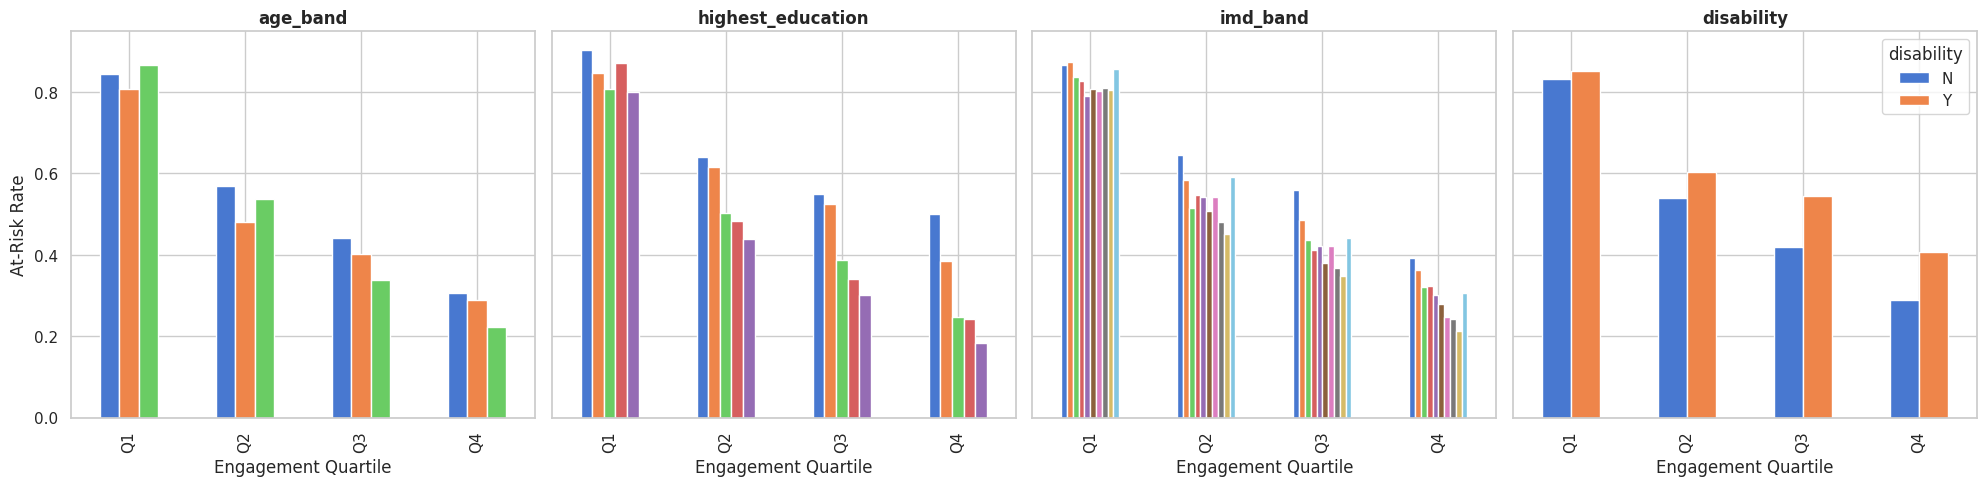

In [ ]:
# Stratified Robustness Check
reg_data['engagement_quartile'] = pd.qcut(reg_data['clicks_w4'], 4, labels=['Q1', 'Q2', 'Q3', 'Q4'], duplicates='drop')

fig, axes = plt.subplots(1, len(demo_vars), figsize=(20, 5), sharey=True)
for i, var in enumerate(demo_vars):
    strat = reg_data.groupby(['engagement_quartile', var])['at_risk'].mean().unstack()
    strat.plot(kind='bar', ax=axes[i], legend=(i == len(demo_vars) - 1))
    axes[i].set_title(var, fontweight='bold')
    axes[i].set_xlabel('Engagement Quartile')
    if i == 0:
        axes[i].set_ylabel('At-Risk Rate')

plt.tight_layout()
plt.show()

Interpretation:

* The raw bivariate charts show that lower age (0–35), lower prior education (No Formal Quals), higher area deprivation (IMD 0–10%), and having a disability are all visually associated with higher raw at-risk rates.

* Disability remains a potent risk factor (coef = 0.3001, p < 0.001), and the stratified robustness check confirms that students with a disability consistently face higher risk across all four engagement quartiles.

* All wealthier IMD bands display significant negative coefficients (p < 0.05) against the most deprived baseline (0–10%), providing strong evidence that socioeconomic advantages buffer risk even at identical engagement levels.

* Having an A-Level qualification up to a Postgraduate degree significantly reduces risk (p < 0.001) compared to no formal qualifications, though holding a qualification lower than A-Level loses its distinct effect (p = 0.178).

* The highest age band (55≤) does not reach statistical significance (p = 0.676) relative to the youngest baseline. Given its wide confidence interval, this most likely reflects a small sample size for this age group rather than genuine absence of an effect — this analysis alone cannot establish that engagement or module choice explains away the raw age association.

These findings provide strong evidence that demographic and socioeconomic disparities are not merely a reflection of low platform activity. Even when comparing students with identical early VLE engagement and within the same module difficulty, disability status, neighborhood deprivation, and prior educational attainment all remain potent and independent drivers of student risk — pointing to systemic barriers that an engagement-only early-warning system would fail to capture.

## 5. Predictive Analytics
(See IMW_MLDLModel.ipynb  notebok)